# Pipeline 2: OCR vs. Bild auf REAL-MM-RAG TechSlides

Follow-up to `test1.ipynb` (SlideVQA pilot), based on the professor's remarks:
*verschiedene Modelle testen (Bild rein, was kommt raus), Erfahrungen sammeln, OCR vs. Bilder.*

| Stage | What it does | Thesis link |
|---|---|---|
| 1. Data | Load TechSlides (1,963 pages, 1,354 queries with 3 rephrasings + answer), save page images | Datengrundlage |
| 2. Filter | SigLIP zero-shot ranks pages by "is a UI screenshot", a small VLM confirms the top candidates and flags highlighted elements, you check a thumbnail grid | how-to subset |
| 3. Extraction | Per slide: Tesseract, EasyOCR, and every VLM with a *transcribe* prompt (VLM as OCR) and a *how-to description* prompt. Answer coverage = how much of the gold answer ends up in the extracted text | "Bild rein, was kommt raus", FF2 |
| 4. QA on the gold slide | Same model, same question, four inputs: image / OCR text / image+OCR / own description. Only the input modality changes | **OCR vs. Bild**, model comparison |
| 5. Retrieval | Text indexes (OCR, description, OCR+description, VLM transcription) with bge-m3, Hit@k and MRR per rephrase level | FF1, variants A/C |
| 6. Optional | ColQwen2.5 page-image retrieval (vision-native) | FF4 |
| 7. Review | Side-by-side gallery and a CSV for marking hallucinations by hand | Faktentreue |

All models are open and run locally (exposé: no external API). Everything is cached on Drive, so a disconnected Colab session resumes where it stopped.
Runs on a Colab **T4**; 7B/8B models need an L4/A100 or `LOAD_4BIT = True`.

In [3]:
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip -q install -U "transformers>=4.57" accelerate sentence-transformers datasets pytesseract easyocr pandas pillow==10.4.0
# optional, only if LOAD_4BIT = True:  !pip -q install -U bitsandbytes

## 0. Configuration

In [4]:
import os, re, io, json, gc, time, random
import numpy as np, pandas as pd, torch
from PIL import Image
from IPython.display import display
from google.colab import drive

if not os.path.exists("/content/drive"):
    drive.mount("/content/drive")

BASE      = "/content/drive/MyDrive/thesis/techslides_pipeline"   # caches + results (survive the runtime)
CACHE_DIR = f"{BASE}/cache"
RES_DIR   = f"{BASE}/results"
PAGE_DIR  = "/content/techslides_pages"                          # page PNGs, local disk (fast, rebuilt per session)
for d in (CACHE_DIR, RES_DIR, PAGE_DIR):
    os.makedirs(d, exist_ok=True)

DATASET_ID = "ibm-research/REAL-MM-RAG_TechSlides"
EMB_ID     = "BAAI/bge-m3"          # same multilingual embedder as in test1
SIGLIP_ID  = "google/siglip-so400m-patch14-384"
OCR_LANG   = "eng"
MAX_SIDE   = 1280                   # every model gets the same resized image; raise for small UI text (slower)
KS         = (1, 3, 5, 10)
SEED       = 42

# Vision-language models. Short key -> Hugging Face id. All open weights.
VLMS = {
    "qwen25vl-3b":  "Qwen/Qwen2.5-VL-3B-Instruct",       # baseline from test1
    "qwen3vl-4b":   "Qwen/Qwen3-VL-4B-Instruct",         # newer Qwen generation
    "internvl3-2b": "OpenGVLab/InternVL3-2B-hf",         # InternVL family (exposé)
    "smolvlm2-2b":  "HuggingFaceTB/SmolVLM2-2.2B-Instruct",  # very small, edge-sized
    # optional:
    "gemma3-4b":    "google/gemma-3-4b-it",              # gated (accept terms on HF); fp16 on T4 can be unstable
    "qwen25vl-7b":  "Qwen/Qwen2.5-VL-7B-Instruct",       # needs L4/A100 or LOAD_4BIT
    "llava-ov-7b":  "llava-hf/llava-onevision-qwen2-7b-ov-hf",  # LLaVA family; L4/A100 or LOAD_4BIT
}
ACTIVE_VLMS = ["qwen25vl-3b", "internvl3-2b", "qwen3vl-4b"]
SCREEN_VLM   = "qwen25vl-3b"        # model used to confirm screenshot slides (stage 2)
POOL_VLMS    = ["qwen25vl-3b"]      # models that describe the whole retrieval pool (expensive, ~10 s/slide each)
POOL_PROMPTS = ["howto"]            # add "transcribe" to also index VLM-as-OCR text
LOAD_4BIT    = False

MAX_QUESTIONS = 60                  # questions on screenshot slides used in stages 3-5
POOL          = "screens"             # "decks": all pages of the decks those questions come from
                                    # "screens": only screenshot pages (hard distractors)
                                    # "global": all 1,963 pages (slow for VLM descriptions)
QA_OCR        = "tesseract"         # OCR text given to the models in the QA "ocr" conditions

DTYPE = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else torch.float16
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none", "| dtype:", DTYPE)

Mounted at /content/drive
GPU: Tesla T4 | dtype: torch.bfloat16


## 1. Load TechSlides and save page images

In [5]:
from datasets import load_dataset

ds = load_dataset(DATASET_ID, split="test")          # ~1.5 GB parquet, one row per query (or per page without query)
meta = ds.remove_columns("image").to_pandas()
print(len(meta), "rows; columns:", list(meta.columns))

def page_id_of(fname):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", os.path.splitext(fname)[0]).strip("_")

def deck_of(fname):
    return os.path.splitext(fname)[0].rsplit("_page_", 1)[0]

def page_no_of(fname):
    m = re.search(r"_page_(\d+)", fname)
    return int(m.group(1)) if m else -1

first_row = meta.groupby("image_filename").head(1)
t0, new = time.time(), 0
for idx, fname in zip(first_row.index, first_row["image_filename"]):
    path = f"{PAGE_DIR}/{page_id_of(fname)}.png"
    if not os.path.exists(path):
        ds[int(idx)]["image"].convert("RGB").save(path)
        new += 1
print(f"saved {new} new page images in {time.time() - t0:.0f}s")

pages_df = pd.DataFrame({
    "page_id": [page_id_of(f) for f in first_row["image_filename"]],
    "filename": first_row["image_filename"].values,
    "deck": [deck_of(f) for f in first_row["image_filename"]],
    "page_no": [page_no_of(f) for f in first_row["image_filename"]],
})
pages_df["path"] = PAGE_DIR + "/" + pages_df.page_id + ".png"
pages = pages_df.set_index("page_id").to_dict("index")

q_df = meta[meta["query"].notna()].copy()
q_df["qid"] = q_df["id"].astype(str)
q_df["gold_page"] = q_df["image_filename"].map(page_id_of)
q_df["deck"] = q_df["image_filename"].map(deck_of)
q_df = q_df[["qid", "deck", "gold_page", "query", "rephrase_level_1", "rephrase_level_2", "rephrase_level_3", "answer"]]
print(f"{len(pages_df)} pages in {pages_df.deck.nunique()} decks, {len(q_df)} queries")
q_df.head(3)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/8.64k [00:00<?, ?B/s]

data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  155MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  210MB            

...

data/test-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  407MB            

data/test-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/2617 [00:00<?, ? examples/s]

2617 rows; columns: ['id', 'image_filename', 'query', 'rephrase_level_1', 'rephrase_level_2', 'rephrase_level_3', 'answer']
saved 1963 new page images in 424s
1963 pages in 61 decks, 1354 queries


,qid,deck,gold_page,query,rephrase_level_1,rephrase_level_2,rephrase_level_3,answer
0,0,How to Future Proof Your ECM Solution,How_to_Future_Proof_Your_ECM_Solution_page_15,What are the benefits of using the Controller ...,What advantages does employing the Controller ...,What advantages can be gained by implementing ...,How does implementing a Controller service lay...,The benefits include the ability to manage con...
1,1,How to Future Proof Your ECM Solution,How_to_Future_Proof_Your_ECM_Solution_page_32,What are the additional capabilities mentioned...,"According to the IBM TechXchange document, wha...",What extra features are highlighted for managi...,"Beyond the standard features, what enhanced fu...",The additional capabilities mentioned for docu...
2,2,How to Future Proof Your ECM Solution,How_to_Future_Proof_Your_ECM_Solution_page_32,How does the IBM TechXchange document suggest ...,What is the recommended approach by the IBM Te...,What approach does the IBM TechXchange documen...,What approach is recommended by the IBM TechXc...,The IBM TechXchange document suggests handling...


## 2. Find the how-to / screenshot slides
**Stage 1** ranks all pages with SigLIP zero-shot (fast). **Stage 2** asks a small VLM about the top `SCREEN_TOPK` candidates: is there a UI screenshot, and is an element highlighted? **Stage 3** is you: look at the grid and fix mistakes in `MANUAL_INCLUDE` / `MANUAL_EXCLUDE`.

In [6]:
from transformers import AutoModel, AutoProcessor

SIG_CACHE = f"{CACHE_DIR}/siglip_scores.csv"
UI_LABELS = ["a screenshot of a software application user interface",
             "a screenshot of a web application with menus and buttons",
             "a screenshot of a settings dialog with input fields"]
OTHER_LABELS = ["a presentation slide with bullet point text",
                "a business chart or bar chart",
                "an architecture diagram with boxes and arrows",
                "a title slide with a company logo",
                "a photo of people"]

if os.path.exists(SIG_CACHE):
    sig = pd.read_csv(SIG_CACHE)
else:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    sproc = AutoProcessor.from_pretrained(SIGLIP_ID)
    smodel = AutoModel.from_pretrained(SIGLIP_ID, dtype=torch.float16 if dev == "cuda" else torch.float32).to(dev).eval()
    labels = UI_LABELS + OTHER_LABELS
    def feats(x):   # newer transformers return an output object instead of a tensor
        return x if torch.is_tensor(x) else x.pooler_output
    with torch.no_grad():
        t_in = sproc(text=labels, padding="max_length", return_tensors="pt").to(dev)
        t_emb = torch.nn.functional.normalize(feats(smodel.get_text_features(**t_in)), dim=-1)
        rows, ids = [], list(pages)
        for i in range(0, len(ids), 16):
            batch = ids[i:i + 16]
            imgs = [Image.open(pages[p]["path"]).convert("RGB") for p in batch]
            px = sproc(images=imgs, return_tensors="pt")["pixel_values"].to(dev, smodel.dtype)
            i_emb = torch.nn.functional.normalize(feats(smodel.get_image_features(pixel_values=px)), dim=-1)
            probs = torch.sigmoid(i_emb @ t_emb.T * smodel.logit_scale.exp() + smodel.logit_bias).float().cpu().numpy()
            for p, pr in zip(batch, probs):
                rows.append({"page_id": p, "ui_score": float(pr[:len(UI_LABELS)].max()),
                             "other_score": float(pr[len(UI_LABELS):].max())})
    sig = pd.DataFrame(rows)
    sig.to_csv(SIG_CACHE, index=False)
    del smodel, sproc; gc.collect(); torch.cuda.empty_cache()

sig = sig.sort_values("ui_score", ascending=False).reset_index(drop=True)
print(sig.head(10))

                                             page_id  ui_score  other_score
0  Leveraging_AI_for_Trade_Finance_with_Industry_...  0.464844     0.000301
1  Streamlining_Insurance_Claims_with_Business_Au...  0.434082     0.000084
2  Introducing_CMOD_REST_into_an_Application_Port...  0.370117     0.658203
3      AIOps_Netcool_Progression_to_CP4AIOps_page_25  0.317383     0.000087
4                          IBM_BAW_for_Batch_page_30  0.271973     0.000048
5  Future_of_Processes_Monolith_to_Micro-Processe...  0.250977     0.000328
6  Extract_Meaningful_Info_to_Automate_Processes_...  0.228149     0.000067
7  Future_of_Processes_Monolith_to_Micro-Processe...  0.226807     0.122498
8  Future_of_Processes_Monolith_to_Micro-Processe...  0.223999     0.045685
9      How_to_Future_Proof_Your_ECM_Solution_page_16  0.196777     0.194336


### VLM helpers (used by every later stage)

In [7]:
from transformers import AutoProcessor, AutoModelForImageTextToText

def load_vlm(key):
    mid = VLMS[key]
    kw = {"device_map": "auto", "dtype": DTYPE}
    if LOAD_4BIT:
        from transformers import BitsAndBytesConfig
        kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=DTYPE)
    torch.cuda.reset_peak_memory_stats()
    proc = AutoProcessor.from_pretrained(mid)
    model = AutoModelForImageTextToText.from_pretrained(mid, **kw).eval()
    return model, proc

def cleanup():
    # call after `del model, proc` so the GPU memory is really released
    gc.collect(); torch.cuda.empty_cache()

def load_image(page_id):
    im = Image.open(pages[page_id]["path"]).convert("RGB")
    im.thumbnail((MAX_SIDE, MAX_SIDE))           # same input size for every model
    return im

@torch.no_grad()
def ask(model, proc, text, image=None, max_new_tokens=256):
    content = ([{"type": "image", "image": image}] if image is not None else []) + [{"type": "text", "text": text}]
    inputs = proc.apply_chat_template([{"role": "user", "content": content}], add_generation_prompt=True,
                                      tokenize=True, return_dict=True, return_tensors="pt")
    inputs = {k: (v.to(model.device, dtype=model.dtype) if torch.is_floating_point(v) else v.to(model.device))
              for k, v in inputs.items()}
    t0 = time.time()
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new = out[:, inputs["input_ids"].shape[1]:]
    return {"text": proc.batch_decode(new, skip_special_tokens=True)[0].strip(),
            "sec": round(time.time() - t0, 2), "tok": int(new.shape[1])}

class Cache:
    # One JSON file per (model, task) on Drive, saved every few entries.
    def __init__(self, name):
        self.path = f"{CACHE_DIR}/{name}.json"
        self.d = json.load(open(self.path)) if os.path.exists(self.path) else {}
        self.n = 0
    def __contains__(self, k): return k in self.d
    def __getitem__(self, k): return self.d[k]
    def get(self, k, default=None): return self.d.get(k, default)
    def put(self, k, v):
        self.d[k] = v; self.n += 1
        if self.n % 5 == 0: self.save()
    def save(self):
        json.dump(self.d, open(self.path, "w"), ensure_ascii=False, indent=1)

def run_cached(cache, keys, fn, label=""):
    todo = [k for k in keys if k not in cache]
    t0 = time.time()
    for i, k in enumerate(todo, 1):
        cache.put(k, fn(k))
        if i % 10 == 0 or i == len(todo):
            print(f"  {label} {i}/{len(todo)}  {(time.time() - t0) / i:.1f}s each")
    cache.save()
    return cache

In [8]:
SCREEN_TOPK = 500     # how many SigLIP candidates the VLM checks (~2 s each on a T4)
SCREEN_PROMPT = (
    "Look at this presentation slide and answer two questions with yes or no.\n"
    "Q1: Does the slide contain a screenshot of a software user interface "
    "(an application window, web page, dialog, menus, buttons or input fields)?\n"
    "Q2: Is a specific element in the screenshot highlighted, for example with a coloured box, arrow, circle or number?\n"
    "Answer in exactly this format:\nQ1: yes or no\nQ2: yes or no")

screen_cache = Cache(f"screen_{SCREEN_VLM}")
cand = sig.page_id.head(SCREEN_TOPK).tolist()
if any(p not in screen_cache for p in cand):
    model, proc = load_vlm(SCREEN_VLM)
    run_cached(screen_cache, cand, lambda p: ask(model, proc, SCREEN_PROMPT, load_image(p), max_new_tokens=20), "screen")
    del model, proc; cleanup()

def yes(text, q):
    m = re.search(rf"{q}\W*(yes|no)", text, re.I)
    return bool(m and m.group(1).lower() == "yes")

sig["vlm_ui"] = sig.page_id.map(lambda p: yes(screen_cache[p]["text"], "Q1") if p in screen_cache else False)
sig["vlm_highlight"] = sig.page_id.map(lambda p: yes(screen_cache[p]["text"], "Q2") if p in screen_cache else False)
print("confirmed screenshot slides:", sig.vlm_ui.sum(), "| with highlighted element:", (sig.vlm_ui & sig.vlm_highlight).sum())
# How deep in the SigLIP ranking do confirmed screenshots still appear? If many near rank SCREEN_TOPK, raise it.
print("confirmed per 100 SigLIP ranks:", [int(sig.vlm_ui[i:i + 100].sum()) for i in range(0, SCREEN_TOPK, 100)])

confirmed screenshot slides: 247 | with highlighted element: 239
confirmed per 100 SigLIP ranks: [77, 53, 48, 35, 34]


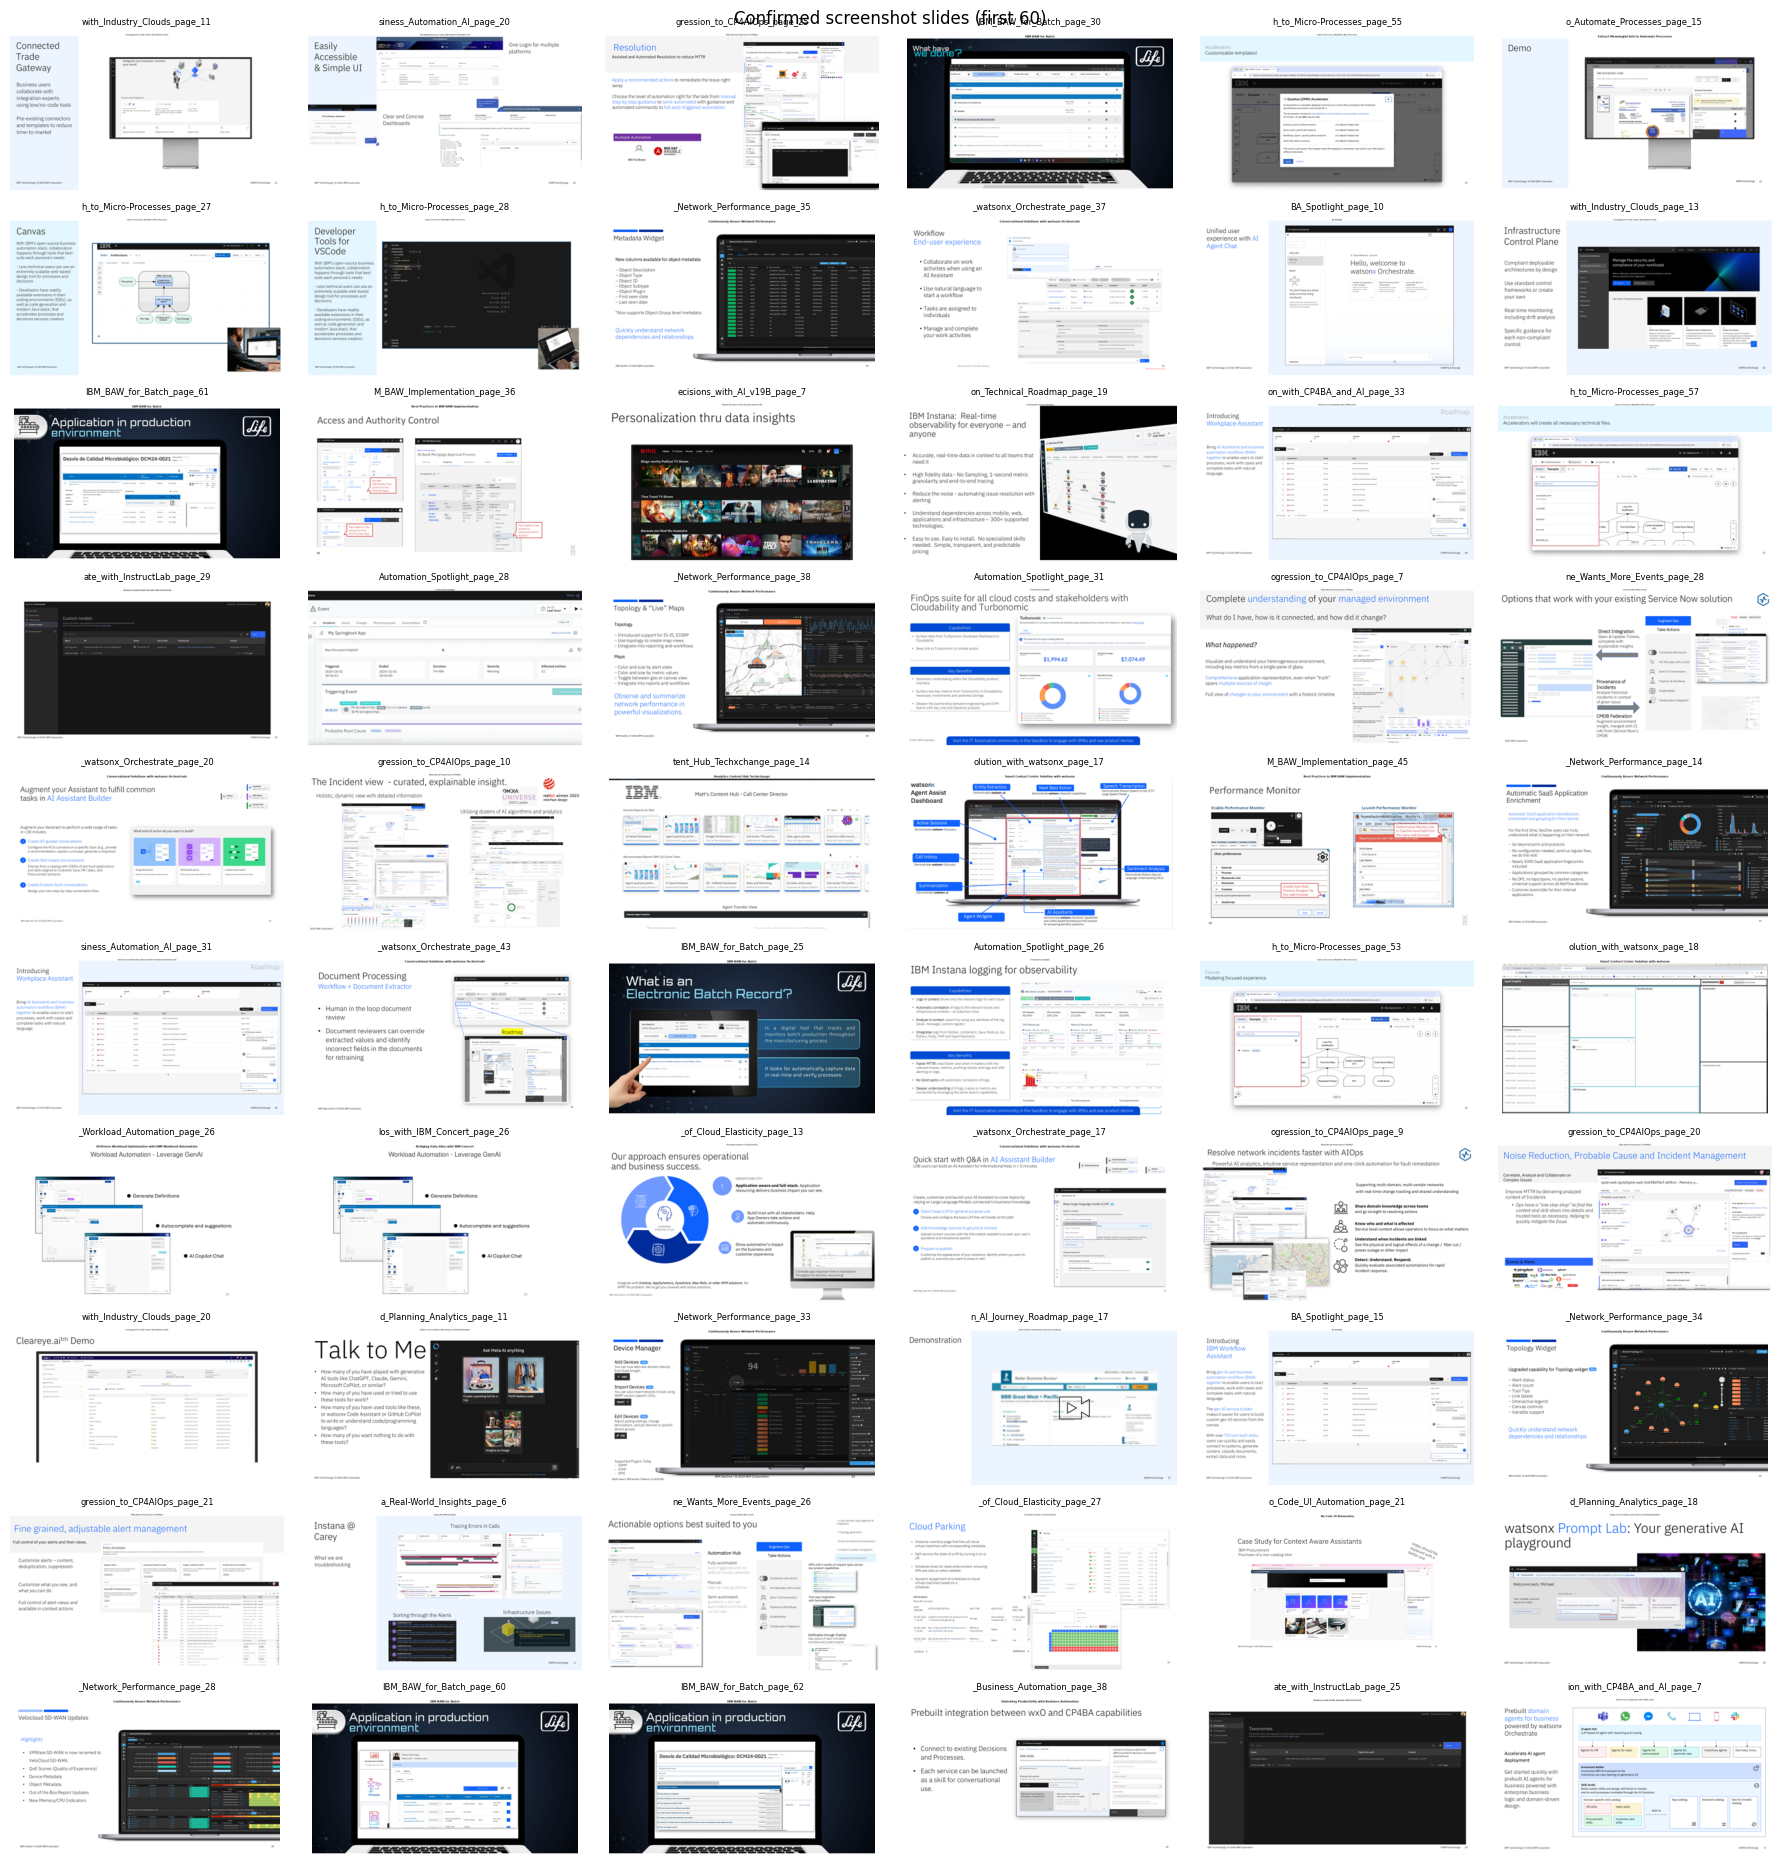

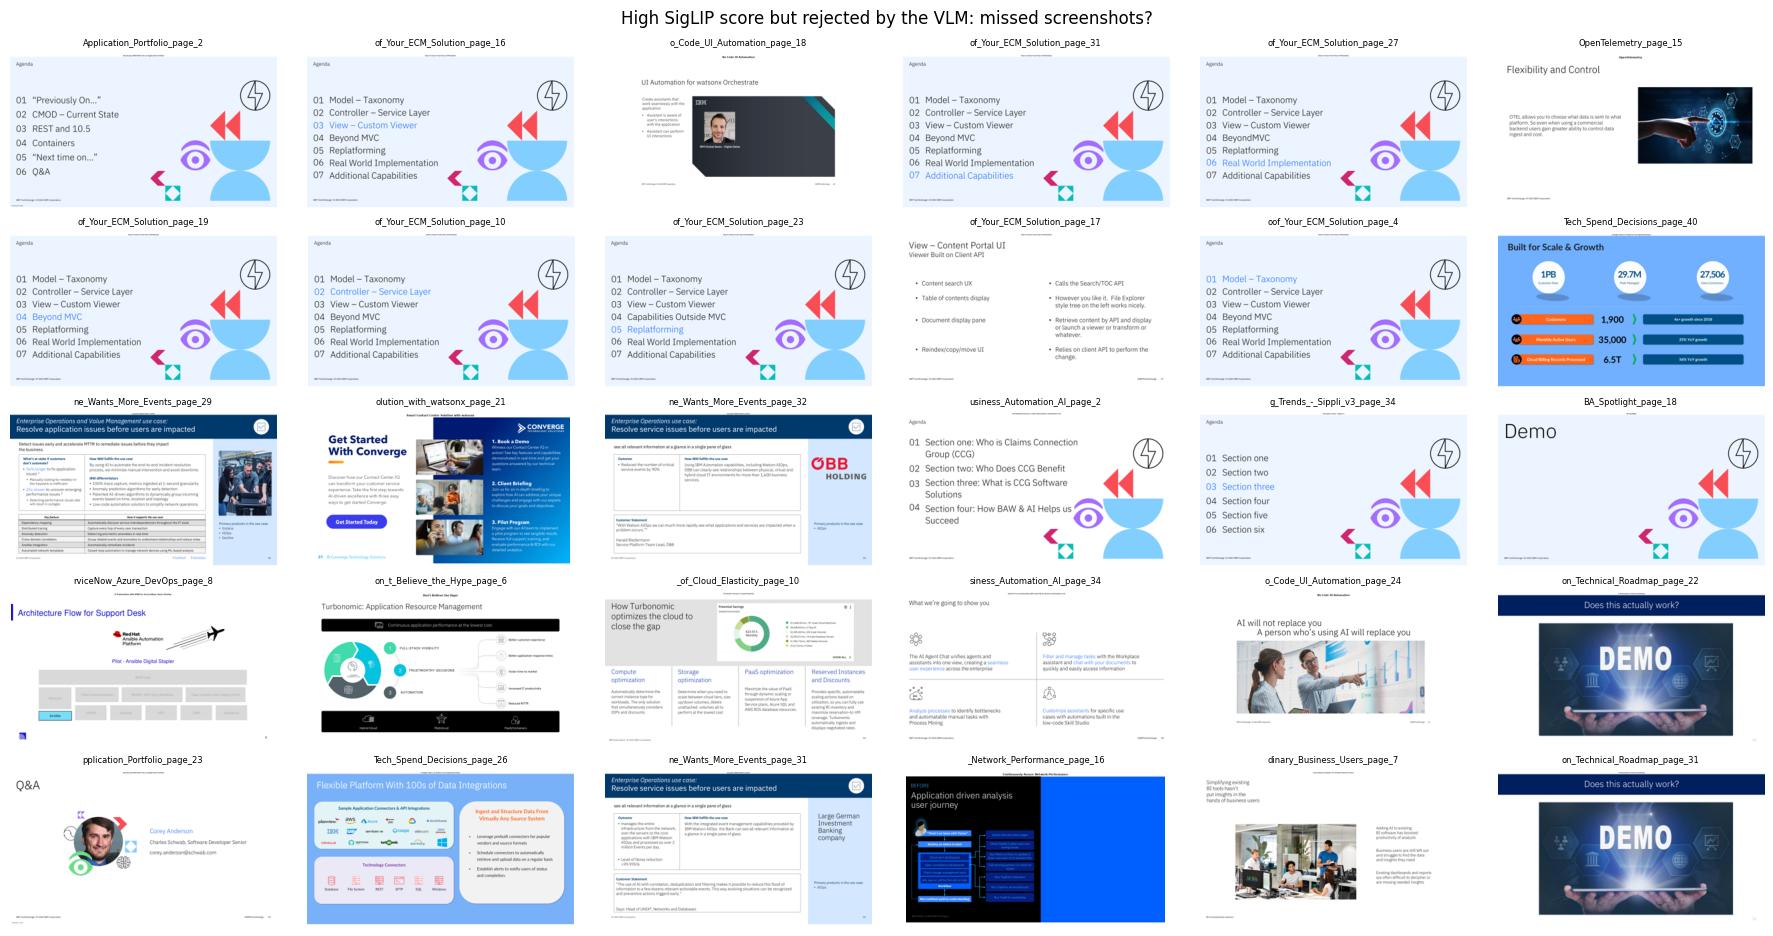

In [9]:
import matplotlib.pyplot as plt

def grid(page_ids, cols=6, title=""):
    rows_n = (len(page_ids) + cols - 1) // cols
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 3, rows_n * 1.9))
    for ax, p in zip(np.ravel(axes), page_ids + [None] * (rows_n * cols - len(page_ids))):
        ax.axis("off")
        if p:
            im = Image.open(pages[p]["path"]); im.thumbnail((400, 400))
            ax.imshow(im); ax.set_title(p[-28:], fontsize=6)
    fig.suptitle(title); plt.tight_layout(); plt.show()
    

screens = sig[sig.vlm_ui].page_id.tolist()
grid(screens[:60], title="Confirmed screenshot slides (first 60)")
grid(sig[~sig.vlm_ui].page_id.head(30).tolist(), title="High SigLIP score but rejected by the VLM: missed screenshots?")

In [10]:
# Fix the automatic labels by hand (page_ids from the grid titles), then re-run this cell.
MANUAL_INCLUDE = set()
MANUAL_EXCLUDE = set()

sig["is_screen"] = (sig.vlm_ui | sig.page_id.isin(MANUAL_INCLUDE)) & ~sig.page_id.isin(MANUAL_EXCLUDE)
sig.to_csv(f"{RES_DIR}/screenshot_labels.csv", index=False)
screen_set = set(sig[sig.is_screen].page_id)
highlight_set = set(sig[sig.is_screen & sig.vlm_highlight].page_id)

q_screen = q_df[q_df.gold_page.isin(screen_set)].copy()
q_screen["highlight"] = q_screen.gold_page.isin(highlight_set)
print(f"{len(screen_set)} screenshot slides, {len(q_screen)} queries whose gold page is one "
      f"({q_screen.highlight.sum()} with a highlighted element), from {q_screen.deck.nunique()} decks")

247 screenshot slides, 103 queries whose gold page is one (102 with a highlighted element), from 28 decks


## 3. Experiment set and retrieval pool

In [11]:
q_set = q_screen.sample(min(MAX_QUESTIONS, len(q_screen)), random_state=SEED).reset_index(drop=True)
gold_pages = sorted(set(q_set.gold_page))

if POOL == "decks":
    pool = pages_df[pages_df.deck.isin(set(q_set.deck))].page_id.tolist()
elif POOL == "screens":
    pool = sorted(screen_set)
else:
    pool = pages_df.page_id.tolist()
assert set(gold_pages) <= set(pool)

q_set.to_csv(f"{RES_DIR}/questions.csv", index=False)
print(f"{len(q_set)} questions, {len(gold_pages)} gold slides, pool = {len(pool)} pages ({POOL})")
print(f"rough cost on a T4: {len(gold_pages) * len(ACTIVE_VLMS) * 2 * 12 / 60:.0f} min extraction on gold slides, "
      f"{len(pool) * len(POOL_VLMS) * len(POOL_PROMPTS) * 12 / 60:.0f} min pool descriptions, "
      f"{len(q_set) * len(ACTIVE_VLMS) * 4 * 4 / 60:.0f} min QA")

60 questions, 43 gold slides, pool = 247 pages (screens)
rough cost on a T4: 52 min extraction on gold slides, 49 min pool descriptions, 48 min QA


## 4. Extraction: OCR engines
Tesseract (as in test1) and EasyOCR (a neural OCR) on every pool page.

In [12]:
import pytesseract, easyocr

ocr = {"tesseract": Cache(f"ocr_tesseract_{OCR_LANG}"), "easyocr": Cache("ocr_easyocr_en")}

def tess(p):
    t0 = time.time()
    txt = pytesseract.image_to_string(Image.open(pages[p]["path"]), lang=OCR_LANG).strip()
    return {"text": txt, "sec": round(time.time() - t0, 2)}
run_cached(ocr["tesseract"], pool, tess, "tesseract")

if any(p not in ocr["easyocr"] for p in pool):
    reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available())
    def easy(p):
        t0 = time.time()
        txt = "\n".join(reader.readtext(pages[p]["path"], detail=0, paragraph=True))
        return {"text": txt, "sec": round(time.time() - t0, 2)}
    run_cached(ocr["easyocr"], pool, easy, "easyocr")
    del reader; cleanup()

p0 = gold_pages[0]
for eng in ocr:
    print(f"--- {eng} on {p0}:\n{ocr[eng][p0]['text'][:500]}\n")

--- tesseract on AI-Driven_Workload_Optimization_with_IBM_Workload_Automation_page_27:
ith IBM Workload Automation

IBM Al DATA ADVISOR (aka AIDA)

Al-AUGMENTED AUTOMATION IWA intelligent add-ons
compatible from 10.1 - available on container

Allows
using &

|

+ HISTORICAL DATA ANALYSIS for jobs & workstations
+ ANOMALY DETECTION on workload execution
+ ALERTING

--- easyocr on AI-Driven_Workload_Optimization_with_IBM_Workload_Automation_page_27:
Al-Driven Workload Optimization with IBM Workload Automation
IBM AI DATA ADVISOR (aka AIDA) Al-AUGMENTED AUTOMATION IWA intelligent add-ons compatible from 10.1 available on container
Bems"
HAteari
Atruarce Cetals
Va Lunt
Wunrut
Ic
Cd CocCt #enttolt
Allows EARLY DETECTION OF POTENTIAL ISSUE(S) using BIG DATA, MACHINE LEARNING & ANALYTICS
7"blibimdmned Lon Somn Lt
73
"iirt ~ii . 1e38n
KEY FEATURES HISTORICAL DATA ANALYSIS for jobs & workstations
ANOMALY DETECTION on workload execution
ALERTING



## 5. Extraction with VLMs + QA on the gold slide
One model is loaded at a time. For each model:
* **transcribe** (VLM as OCR) and **howto** description on every gold slide (plus the whole pool for `POOL_VLMS`);
* **QA**, four conditions with the *same* model and question: `image`, `ocr` (text only), `image+ocr`, `desc` (its own howto description as text, i.e. what a text-RAG index would hold).

In [ ]:
PROMPTS = {
    "transcribe": ("Transcribe all text visible in this image exactly as written, including text inside screenshots, "
                   "menus, buttons, tables and labels. Output plain text only, one line per text block. "
                   "Do not add explanations."),
    "howto": ("This is a slide from technical software documentation. Describe it so that someone who cannot see it "
              "can find and use its information: 1) which application and which screen or dialog is shown, "
              "2) the visible menus, tabs, buttons and fields with their exact labels, 3) any highlighted element "
              "(box, arrow, circle, number) and the action it points to, 4) values, settings or steps shown. "
              "Read labels exactly. Do not guess anything that is not visible."),
    "generic": "Describe this image.",      # FF2 baseline; add to EXTRACT_PROMPTS to compare
}

EXTRACT_PROMPTS = ["howto"]




QA_IMAGE = ("Answer the question using only this slide. Answer briefly, in one sentence or a few words. "
            "If the slide does not contain the answer, reply 'not on the slide'.\n\nQuestion: {q}")
QA_TEXT = ("Here is {what} of a presentation slide:\n\"\"\"\n{ctx}\n\"\"\"\n\n"
           "Answer the question using only this text. Answer briefly, in one sentence or a few words. "
           "If the text does not contain the answer, reply 'not on the slide'.\n\nQuestion: {q}")
QA_BOTH = ("Here is the OCR text of the slide shown in the image:\n\"\"\"\n{ctx}\n\"\"\"\n\n" + QA_IMAGE)
CTX_CHARS = 4000
QA_CONDITIONS = ["image", "ocr", "image+ocr", "desc"]

ext = {}        # (model, prompt) -> Cache
qa = {}         # model -> Cache
model_stats = []
qrow = q_set.set_index("qid").to_dict("index")

for key in ACTIVE_VLMS:
    prompts_k = set(EXTRACT_PROMPTS) | {"howto"} | (set(POOL_PROMPTS) if key in POOL_VLMS else set())
    for pr in prompts_k:
        ext[(key, pr)] = Cache(f"ext_{key}_{pr}")
    qa[key] = Cache(f"qa_{key}")
    need = {pr: (pool if key in POOL_VLMS and pr in POOL_PROMPTS else gold_pages) for pr in prompts_k}
    qa_keys = [f"{qid}|{c}" for qid in q_set.qid for c in QA_CONDITIONS]
    if all(p in ext[(key, pr)] for pr, ps in need.items() for p in ps) and all(k in qa[key] for k in qa_keys):
        print(key, "fully cached"); continue

    print(f"\n=== {key}: {VLMS[key]}")
    try:
        t0 = time.time(); model, proc = load_vlm(key); load_s = time.time() - t0
    except Exception as e:
        print("  could not load:", repr(e)[:300]); continue

    for pr, ps in need.items():
        # gold slides first, so the model comparison is complete even if the pool run is interrupted
        ps = gold_pages + [p for p in ps if p not in set(gold_pages)]
        run_cached(ext[(key, pr)], ps, lambda p: ask(model, proc, PROMPTS[pr], load_image(p), 512), f"{key}/{pr}")

    def answer(k):
        qid, cond = k.split("|")
        q, gp = qrow[qid]["query"], qrow[qid]["gold_page"]
        ocr_txt = ocr[QA_OCR][gp]["text"][:CTX_CHARS]
        if cond == "image":
            return ask(model, proc, QA_IMAGE.format(q=q), load_image(gp), 96)
        if cond == "ocr":
            return ask(model, proc, QA_TEXT.format(what="the OCR text", ctx=ocr_txt, q=q), None, 96)
        if cond == "image+ocr":
            return ask(model, proc, QA_BOTH.format(ctx=ocr_txt, q=q), load_image(gp), 96)
        if cond == "desc":
            d = ext[(key, "howto")][gp]["text"][:CTX_CHARS]
            return ask(model, proc, QA_TEXT.format(what="a description", ctx=d, q=q), None, 96)
    run_cached(qa[key], qa_keys, answer, f"{key}/qa")

    model_stats.append({"model": key, "load_s": round(load_s), "peak_vram_gb": round(torch.cuda.max_memory_allocated() / 1e9, 1)})
    pd.DataFrame(model_stats).to_csv(f"{RES_DIR}/model_stats_{time.strftime('%Y%m%d_%H%M')}.csv", index=False)
    del model, proc; cleanup()

qwen25vl-3b fully cached

=== internvl3-2b: OpenGVLab/InternVL3-2B-hf


processor_config.json:   0%|          | 0.00/72.0 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/481 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.96k [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

  qwen3vl-4b/qa 10/240  19.9s each
  qwen3vl-4b/qa 20/240  19.4s each
  qwen3vl-4b/qa 30/240  19.3s each
  qwen3vl-4b/qa 40/240  19.0s each
  qwen3vl-4b/qa 50/240  19.0s each
  qwen3vl-4b/qa 60/240  19.0s each
  qwen3vl-4b/qa 70/240  19.1s each
  qwen3vl-4b/qa 80/240  19.2s each
  qwen3vl-4b/qa 90/240  19.1s each
  qwen3vl-4b/qa 100/240  19.1s each
  qwen3vl-4b/qa 110/240  19.1s each
  qwen3vl-4b/qa 120/240  19.1s each
  qwen3vl-4b/qa 130/240  19.2s each
  qwen3vl-4b/qa 140/240  19.4s each
  qwen3vl-4b/qa 150/240  19.4s each
  qwen3vl-4b/qa 160/240  19.5s each
  qwen3vl-4b/qa 170/240  19.5s each
  qwen3vl-4b/qa 180/240  19.6s each
  qwen3vl-4b/qa 190/240  19.6s each
  qwen3vl-4b/qa 200/240  19.6s each
  qwen3vl-4b/qa 210/240  19.6s each
  qwen3vl-4b/qa 220/240  19.7s each
  qwen3vl-4b/qa 230/240  19.7s each
  qwen3vl-4b/qa 240/240  19.7s each


## 6. Results: extraction and QA

In [14]:
import string
from collections import Counter

STOP = set("a an the of to in on for and or is are be by with from at as this that it its".split())
def toks(s):
    s = str(s or "").lower().translate(str.maketrans(string.punctuation, " " * len(string.punctuation)))
    return [t for t in s.split() if t not in STOP]

def f1(pred, gold):
    p, g = toks(pred), toks(gold)
    common = sum((Counter(p) & Counter(g)).values())
    if not p or not g or not common: return 0.0
    prec, rec = common / len(p), common / len(g)
    return 2 * prec * rec / (prec + rec)

def recall(pred, gold):
    # share of gold-answer tokens that appear in pred (also used as "answer coverage" of an extraction)
    g, p = toks(gold), set(toks(pred))
    return sum(t in p for t in g) / len(g) if g else 0.0

def refused(pred):
    return "not on the slide" in str(pred).lower()

# 6a. Extraction: how much of the gold answer is in the extracted text? (no ground-truth text exists, so this is a proxy)
rows = []
for _, q in q_set.iterrows():
    gp = q.gold_page
    for eng, c in ocr.items():
        rows.append({"source": f"OCR {eng}", "qid": q.qid, "coverage": recall(c[gp]["text"], q.answer),
                     "chars": len(c[gp]["text"]), "sec": c[gp]["sec"]})
    for (key, pr), c in ext.items():
        if gp in c:
            rows.append({"source": f"{key} {pr}", "qid": q.qid, "coverage": recall(c[gp]["text"], q.answer),
                         "chars": len(c[gp]["text"]), "sec": c[gp]["sec"]})
cov = pd.DataFrame(rows)
cov_sum = cov.groupby("source").agg(answer_coverage=("coverage", "mean"), chars=("chars", "mean"),
                                    sec_per_slide=("sec", "mean")).round(2).sort_values("answer_coverage", ascending=False)
cov_sum.to_csv(f"{RES_DIR}/extraction_summary.csv")
display(cov_sum)

# 6b. QA on the gold slide: same model, different input
rows = []
for key, c in qa.items():
    for k, v in c.d.items():
        qid, cond = k.split("|")
        if qid not in qrow: continue
        gold = qrow[qid]["answer"]
        rows.append({"model": key, "cond": cond, "qid": qid, "pred": v["text"], "F1": f1(v["text"], gold),
                     "recall": recall(v["text"], gold), "refused": refused(v["text"]), "sec": v["sec"],
                     "highlight": qrow[qid]["gold_page"] in highlight_set})
qa_res = pd.DataFrame(rows)
qa_res.to_csv(f"{RES_DIR}/qa_results.csv", index=False)
print(f"QA on {qa_res.qid.nunique()} questions. F1/recall are token overlap with the reference answer.")
for metric in ("F1", "recall", "refused"):
    print("\n", metric)
    display(qa_res.pivot_table(index="model", columns="cond", values=metric, aggfunc="mean").round(2)[QA_CONDITIONS])
print("\nrecall, slides with vs. without a highlighted element")
display(qa_res.pivot_table(index=["model", "highlight"], columns="cond", values="recall", aggfunc="mean").round(2))

,answer_coverage,chars,sec_per_slide
source,,,
OCR easyocr,0.76,1133.38,2.40
OCR tesseract,0.74,644.23,1.79
qwen25vl-3b howto,0.68,1698.95,26.81
internvl3-2b howto,0.51,1837.42,23.71
qwen3vl-4b howto,0.41,2042.55,71.91


QA on 60 questions. F1/recall are token overlap with the reference answer.

 F1


cond,image,ocr,image+ocr,desc
model,,,,
internvl3-2b,0.61,0.59,0.67,0.48
qwen25vl-3b,0.59,0.61,0.66,0.42
qwen3vl-4b,0.56,0.52,0.55,0.25



 recall


cond,image,ocr,image+ocr,desc
model,,,,
internvl3-2b,0.59,0.60,0.70,0.53
qwen25vl-3b,0.58,0.62,0.67,0.40
qwen3vl-4b,0.49,0.48,0.50,0.26



 refused


cond,image,ocr,image+ocr,desc
model,,,,
internvl3-2b,0.00,0.03,0.0,0.20
qwen25vl-3b,0.03,0.07,0.0,0.22
qwen3vl-4b,0.02,0.08,0.0,0.42



recall, slides with vs. without a highlighted element


cond                    desc  image  image+ocr   ocr
model        highlight                              
internvl3-2b False      1.00   0.89       0.94  1.00
             True       0.52   0.59       0.69  0.59
qwen25vl-3b  False      0.17   0.72       0.89  0.89
             True       0.40   0.57       0.66  0.61
qwen3vl-4b   False      0.00   0.67       0.67  0.67
             True       0.26   0.49       0.50  0.48

## 7. Retrieval: text indexes over the pool

In [15]:
from sentence_transformers import SentenceTransformer

DESC_PREFIX = "Description of the slide: "
def T(c, p): return c[p]["text"] if p in c else ""

VARIANTS = {f"A_ocr_{eng}": (lambda p, c=c: [T(c, p)]) for eng, c in ocr.items()}
for key in POOL_VLMS:
    if (key, "howto") in ext and all(p in ext[(key, "howto")] for p in pool):
        d = ext[(key, "howto")]
        VARIANTS[f"C_merged_{key}"]  = lambda p, d=d: [T(ocr["tesseract"], p) + "\n\n" + DESC_PREFIX + T(d, p)]
        VARIANTS[f"C_separate_{key}"] = lambda p, d=d: [T(ocr["tesseract"], p), DESC_PREFIX + T(d, p)]
        VARIANTS[f"desc_only_{key}"] = lambda p, d=d: [T(d, p)]
    if (key, "transcribe") in ext and all(p in ext[(key, "transcribe")] for p in pool):
        VARIANTS[f"vlm_ocr_{key}"] = lambda p, t=ext[(key, "transcribe")]: [T(t, p)]
print("variants:", list(VARIANTS))

emb = SentenceTransformer(EMB_ID, device="cuda")
emb.max_seq_length = 1024
index = {}
for name, make in VARIANTS.items():
    meta_ = [{"page_id": p, "text": t} for p in pool for t in make(p) if t.strip() and t.strip() != DESC_PREFIX.strip()]
    vecs = emb.encode([m["text"] for m in meta_], batch_size=16, normalize_embeddings=True, show_progress_bar=False)
    index[name] = (np.asarray(vecs), meta_)

def rank_pages(q_vec, vecs, meta_):
    scores, best = vecs @ q_vec, {}
    for s, m in zip(scores, meta_):
        if s > best.get(m["page_id"], -1e9):
            best[m["page_id"]] = float(s)
    return [p for p, _ in sorted(best.items(), key=lambda x: -x[1])]

def score(ranking, gold, ks=KS):
    first = next((i for i, p in enumerate(ranking, 1) if p == gold), None)
    out = {f"Hit@{k}": float(first is not None and first <= k) for k in ks}
    out["MRR"] = 1.0 / first if first else 0.0
    out["rank"] = first
    return out

LEVELS = ["query", "rephrase_level_1", "rephrase_level_2", "rephrase_level_3"]
records = []
for _, q in q_set.iterrows():
    for lvl in LEVELS:
        if not isinstance(q[lvl], str): continue
        q_vec = emb.encode(q[lvl], normalize_embeddings=True)
        for name, (vecs, meta_) in index.items():
            records.append({"qid": q.qid, "level": lvl, "variant": name, **score(rank_pages(q_vec, vecs, meta_), q.gold_page)})
ret = pd.DataFrame(records)
ret.to_csv(f"{RES_DIR}/retrieval_{POOL}_{time.strftime('%Y%m%d_%H%M')}.csv", index=False)
print(f"Pool: {len(pool)} pages ({POOL}), {q_set.qid.nunique()} questions x {len(LEVELS)} phrasings")
display(ret.groupby("variant")[[f"Hit@{k}" for k in KS] + ["MRR"]].mean().round(2))
display(ret.pivot_table(index="variant", columns="level", values="MRR").round(2)[LEVELS])

variants: ['A_ocr_tesseract', 'A_ocr_easyocr', 'C_merged_qwen25vl-3b', 'C_separate_qwen25vl-3b', 'desc_only_qwen25vl-3b']


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Pool: 247 pages (screens), 60 questions x 4 phrasings


,Hit@1,Hit@3,Hit@5,Hit@10,MRR
variant,,,,,
A_ocr_easyocr,0.66,0.90,0.95,0.98,0.79
A_ocr_tesseract,0.72,0.94,0.98,1.00,0.83
C_merged_qwen25vl-3b,0.72,0.92,0.97,0.98,0.82
C_separate_qwen25vl-3b,0.70,0.94,0.99,1.00,0.82
desc_only_qwen25vl-3b,0.57,0.75,0.80,0.90,0.68


level,query,rephrase_level_1,rephrase_level_2,rephrase_level_3
variant,,,,
A_ocr_easyocr,0.81,0.80,0.78,0.75
A_ocr_tesseract,0.87,0.85,0.80,0.81
C_merged_qwen25vl-3b,0.85,0.83,0.80,0.81
C_separate_qwen25vl-3b,0.88,0.82,0.79,0.80
desc_only_qwen25vl-3b,0.70,0.70,0.66,0.67


## 8. Optional (FF4): vision-native retrieval with ColQwen2.5
Embeds the page images directly, no OCR or description. `colpali-engine` may install a different `transformers` version:
run this section **after** the others, or in a fresh runtime (caches on Drive are reused).

In [16]:
RUN_COLQWEN = False
if RUN_COLQWEN:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "colpali-engine"], check=True)
    from colpali_engine.models import ColQwen2_5, ColQwen2_5_Processor
    cq = ColQwen2_5.from_pretrained("vidore/colqwen2.5-v0.2", torch_dtype=DTYPE, device_map="cuda").eval()
    cqp = ColQwen2_5_Processor.from_pretrained("vidore/colqwen2.5-v0.2")
    page_embs = []
    with torch.no_grad():
        for i in range(0, len(pool), 4):
            batch = cqp.process_images([load_image(p) for p in pool[i:i + 4]]).to(cq.device)
            page_embs += list(torch.unbind(cq(**batch).to("cpu")))
    recs = []
    with torch.no_grad():
        for _, q in q_set.iterrows():
            for lvl in LEVELS:
                if not isinstance(q[lvl], str): continue
                qe = cq(**cqp.process_queries([q[lvl]]).to(cq.device)).to("cpu")
                s = cqp.score_multi_vector(list(torch.unbind(qe)), page_embs)[0]
                ranking = [pool[i] for i in torch.argsort(s, descending=True).tolist()]
                recs.append({"qid": q.qid, "level": lvl, "variant": "colqwen2.5_image", **score(ranking, q.gold_page)})
    ret_cq = pd.DataFrame(recs)
    ret_cq.to_csv(f"{RES_DIR}/retrieval_colqwen_{POOL}.csv", index=False)
    display(ret_cq.groupby("variant")[[f"Hit@{k}" for k in KS] + ["MRR"]].mean().round(2))

## 9. Look at the outputs (Erfahrungen sammeln)
Side-by-side for a few questions, plus a CSV to mark hallucinations by hand.

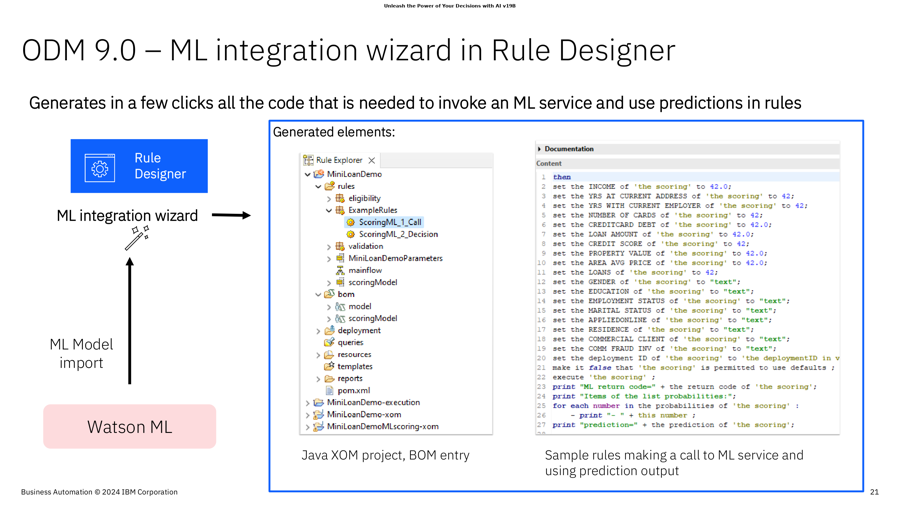

Q: What kind of project is generated by the ML integration wizard?
Reference: The ML integration wizard generates a Java XOM project with a BOM entry.

[qwen25vl-3b]
   image      Java XOM project
   ocr        A Java XOM project is generated by the ML integration wizard.
   image+ocr  A Java XOM project is generated by the ML integration wizard.
   desc       Not on the slide.
   howto desc: The slide is from a technical software documentation for IBM Business Automation, specifically focusing on ODM 9.0. It highlights the ML integration wizard in the Rule Designer.

### Description:

1. **Application and Screen/Diaglog:**
   - The slide shows the "Rule Designer" interface within IBM Business Automation.

2. **Visible Menus, Tabs, Buttons, and Fields:**
   - **ML Integration Wizard:**
[internvl3-2b]
   image      Java XOM project, BOM entry
   ocr        Java XOM project.
   image+ocr  Java XOM project, BOM entry
   desc       The project generated by the ML integration wizard is a Ru

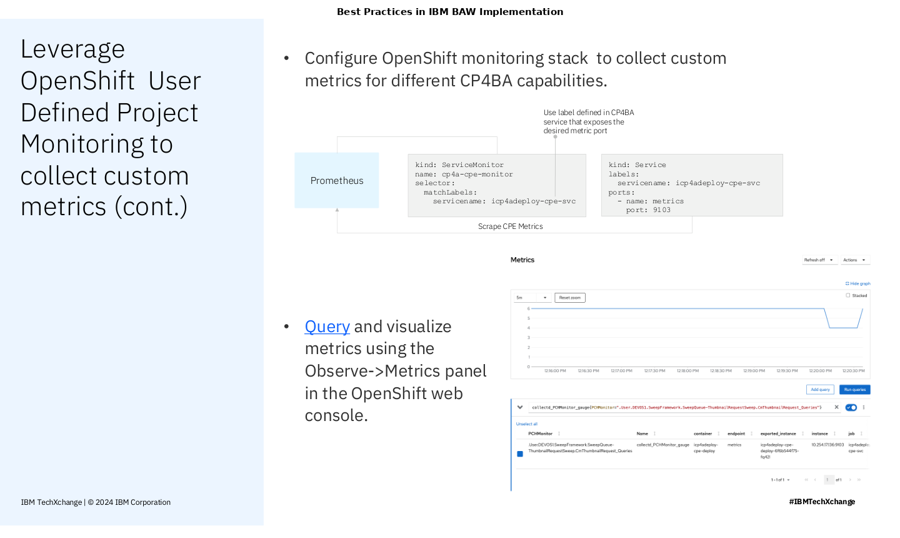

Q: How can the custom metrics be queried and visualized in the OpenShift environment?
Reference: The custom metrics can be queried and visualized using the Observe->Metrics panel in the OpenShift web console.

[qwen25vl-3b]
   image      The custom metrics can be queried and visualized by using the Observe->Metrics panel in the OpenShift web console.
   ocr        The custom metrics can be queried and visualized using the Observe->Metrics panel in the OpenShift web console.
   image+ocr  The custom metrics can be queried and visualized using the Observe->Metrics panel in the OpenShift web console.
   desc       The custom metrics can be queried and visualized using the Observe->Metrics panel in the OpenShift web console.
   howto desc: The slide is from a technical presentation on IBM BAW (Business Application Web) implementation best practices. It focuses on leveraging OpenShift User Defined Project Monitoring to collect custom metrics for CP4BA capabilities.

### Slide Content:
1. **

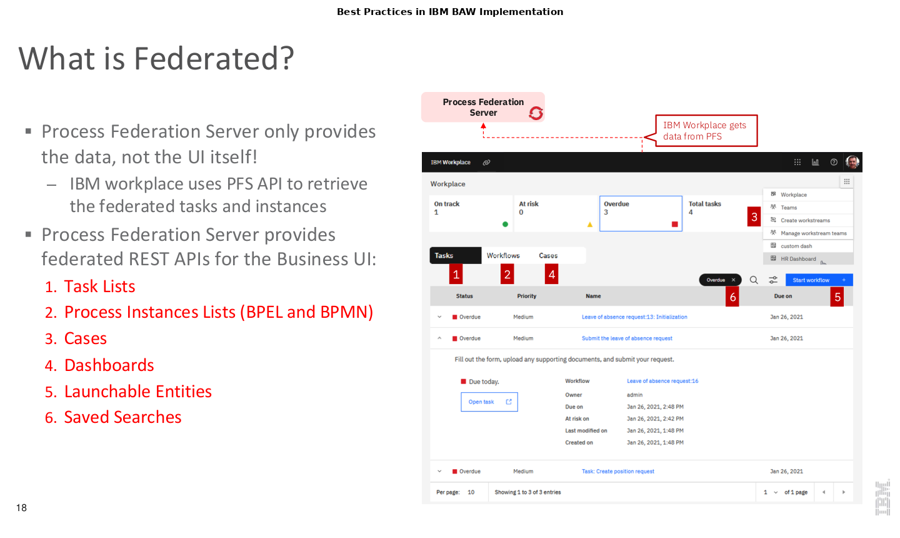

Q: What specific functionalities are provided by the federated REST APIs in the IBM BAW Implementation?
Reference: The federated REST APIs provide functionalities for Task Lists, Process Instances Lists (BPEL and BPMN), Cases, Dashboards, Launchable Entities, and Saved Searches.

[qwen25vl-3b]
   image      The federated REST APIs provide functionalities such as Task Lists, Process Instances Lists (BPEL and BPMN), Cases, Dashboards, Launchable Entities, and Saved Searches.
   ocr        The federated REST APIs provide functionalities such as Task Lists, Process Instances Lists, Cases, Dashboards, Launchable Entities, and Saved Searches.
   image+ocr  The federated REST APIs provide functionalities such as Task Lists, Process Instances Lists, Cases, Dashboards, Launchable Entities, and Saved Searches.
   desc       The federated REST APIs provide access to task lists, process instances lists (BPEL and BPMN), cases, dashboards, launchable entities, and saved searches.
   howto desc: The 

In [17]:
SHOW = 3
for _, q in q_set.head(SHOW).iterrows():
    im = Image.open(pages[q.gold_page]["path"]); im.thumbnail((900, 900)); display(im)
    print(f"Q: {q.query}\nReference: {q.answer}\n")
    for key in qa:
        print(f"[{key}]")
        for cond in QA_CONDITIONS:
            v = qa[key].get(f"{q.qid}|{cond}")
            if v: print(f"   {cond:10s} {v['text'][:200]}")
        d = ext.get((key, "howto"))
        if d and q.gold_page in d: print(f"   howto desc: {d[q.gold_page]['text'][:400]}")
    print("=" * 100)

review = []
for gp in gold_pages[:20]:
    for (key, pr), c in ext.items():
        if pr == "howto" and gp in c:
            review.append({"page_id": gp, "model": key, "description": c[gp]["text"],
                           "hallucinated_items": "", "missed_highlight": "", "notes": ""})
pd.DataFrame(review).to_csv(f"{RES_DIR}/review_sheet.csv", index=False)
print("review sheet:", f"{RES_DIR}/review_sheet.csv")